# Week 7 HW1 - SIR and SEIR Model Implementation for Pandemic Spread

In [1]:
import inspect
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COL = {"S": "tab:blue", "E": "tab:orange", "I": "tab:red", "R": "tab:green"}

## A. Model Implementation

In [6]:
def euler(f, y0, t_end, dt, t0=0.0):
    """Forward Euler: y_{n+1} = y_n + dt * f(t_n, y_n).

    f     : function f(t, y) -> dy/dt (numpy array)
    y0    : initial state (array-like)
    t_end : final time
    dt    : step size
    Returns (t, Y) where Y[n] is the state at time t[n].
    """
    n_steps = int(round((t_end - t0) / dt))
    t = t0 + dt * np.arange(n_steps + 1)
    Y = np.zeros((n_steps + 1, len(y0)))
    Y[0] = y0
    for n in range(n_steps):
        Y[n + 1] = Y[n] + dt * f(t[n], Y[n])
    return t, Y


def rk4(f, y0, t_end, dt, t0=0.0):
    """Classical 4th-order Runge-Kutta.

    Each step averages four slope estimates (start, two midpoints, end),
    so the global error shrinks like dt^4 instead of dt for Euler.
    """
    n_steps = int(round((t_end - t0) / dt))
    t = t0 + dt * np.arange(n_steps + 1)
    Y = np.zeros((n_steps + 1, len(y0)))
    Y[0] = y0
    for n in range(n_steps):
        tn, yn = t[n], Y[n]
        k1 = f(tn, yn)
        k2 = f(tn + dt / 2, yn + dt / 2 * k1)
        k3 = f(tn + dt / 2, yn + dt / 2 * k2)
        k4 = f(tn + dt, yn + dt * k3)
        Y[n + 1] = yn + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return t, Y

def seir_rhs(beta, gamma, sigma, mu, N):
    """Right-hand side of the SEIR model with births and deaths (rate mu):
        dS/dt = mu*N - beta*S*I - mu*S
        dE/dt = beta*S*I - (sigma + mu)*E
        dI/dt = sigma*E - (gamma + mu)*I
        dR/dt = gamma*I - mu*R
    """
    def f(t, y):
        S, E, I, R = y
        new_inf = beta * S * I
        return np.array([
            mu * N - new_inf - mu * S,
            new_inf - (sigma + mu) * E,
            sigma * E - (gamma + mu) * I,
            gamma * I - mu * R,
        ])
    return f


def sir_rhs(beta, gamma):
    """Right-hand side of the SIR model:
        dS/dt = -beta*S*I
        dI/dt =  beta*S*I - gamma*I
        dR/dt =  gamma*I
    """
    def f(t, y):
        S, I, R = y
        new_inf = beta * S * I     # new infections per day
        recov = gamma * I          # recoveries per day
        return np.array([-new_inf, new_inf - recov, recov])
    return f

def simulate_sir(N, S0, I0, R0, beta, gamma, t_end, dt=0.1, solver=rk4):
    """Convenience wrapper: returns t, S, I, R."""
    t, Y = solver(sir_rhs(beta, gamma), np.array([S0, I0, R0], float), t_end, dt)
    return t, Y[:, 0], Y[:, 1], Y[:, 2]


def simulate_seir(N, S0, E0, I0, R0, beta, gamma, sigma, mu, t_end, dt=0.1, solver=rk4):
    """Convenience wrapper: returns t, S, E, I, R."""
    f = seir_rhs(beta, gamma, sigma, mu, N)
    t, Y = solver(f, np.array([S0, E0, I0, R0], float), t_end, dt)
    return t, Y[:, 0], Y[:, 1], Y[:, 2], Y[:, 3]

In [3]:
for fn in (euler, rk4, sir_rhs):
    print(inspect.getsource(fn))

def euler(f, y0, t_end, dt, t0=0.0):
    """Forward Euler: y_{n+1} = y_n + dt * f(t_n, y_n).

    f     : function f(t, y) -> dy/dt (numpy array)
    y0    : initial state (array-like)
    t_end : final time
    dt    : step size
    Returns (t, Y) where Y[n] is the state at time t[n].
    """
    n_steps = int(round((t_end - t0) / dt))
    t = t0 + dt * np.arange(n_steps + 1)
    Y = np.zeros((n_steps + 1, len(y0)))
    Y[0] = y0
    for n in range(n_steps):
        Y[n + 1] = Y[n] + dt * f(t[n], Y[n])
    return t, Y

def rk4(f, y0, t_end, dt, t0=0.0):
    """Classical 4th-order Runge-Kutta.

    Each step averages four slope estimates (start, two midpoints, end),
    so the global error shrinks like dt^4 instead of dt for Euler.
    """
    n_steps = int(round((t_end - t0) / dt))
    t = t0 + dt * np.arange(n_steps + 1)
    Y = np.zeros((n_steps + 1, len(y0)))
    Y[0] = y0
    for n in range(n_steps):
        tn, yn = t[n], Y[n]
        k1 = f(tn, yn)
        k2 = f(tn + dt / 2, yn

In [4]:
from scipy.integrate import solve_ivp   # used ONLY for verification

N, beta, gamma = 2000, 0.125e-3, 0.1
y0 = np.array([1995.0, 5.0, 0.0])
t_ref = np.linspace(0, 160, 1601)
ref = solve_ivp(sir_rhs(beta, gamma), [0, 160], y0, t_eval=t_ref, rtol=1e-10, atol=1e-10).y.T

print(f"{'solver':>6} {'dt':>5}  {'max |error| over S,I,R (people)':>32}")
for name, solver in [("Euler", euler), ("RK4", rk4)]:
    for dt in [1.0, 0.5, 0.1]:
        t, Y = solver(sir_rhs(beta, gamma), y0, 160, dt)
        idx = np.round(t / 0.1).astype(int)
        err = np.abs(Y - ref[idx]).max()
        print(f"{name:>6} {dt:>5}  {err:>32.2e}")

solver    dt   max |error| over S,I,R (people)
 Euler   1.0                          1.07e+02
 Euler   0.5                          5.35e+01
 Euler   0.1                          1.07e+01
   RK4   1.0                          4.13e-03
   RK4   0.5                          2.73e-04
   RK4   0.1                          6.00e-07


Both solvers converge to the high-accuracy `solve_ivp` reference on the Part B problem. Halving $\Delta t$ roughly halves the Euler error (first order) and divides the RK4 error by about 15 (fourth order). With $\Delta t = 0.1$ day, RK4 agrees with the reference to within a millionth of a person, so it is used for everything that follows.

## B. SIR Model Simulation

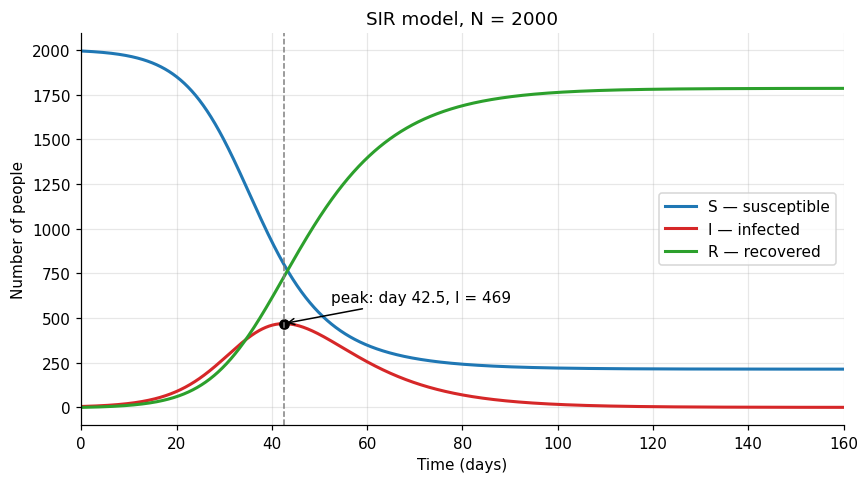

In [7]:
N, S0, I0, R0_init = 2000, 1995, 5, 0
beta, gamma = 0.125e-3, 0.1

t, S, I, R = simulate_sir(N, S0, I0, R0_init, beta, gamma, t_end=160, dt=0.1)
k = I.argmax()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(t, S, color=COL["S"], lw=2, label="S — susceptible")
ax.plot(t, I, color=COL["I"], lw=2, label="I — infected")
ax.plot(t, R, color=COL["R"], lw=2, label="R — recovered")
ax.plot(t[k], I[k], "ko")
ax.annotate(f"peak: day {t[k]:.1f}, I = {I[k]:.0f}", (t[k], I[k]), xytext=(t[k] + 10, I[k] + 120),
            arrowprops=dict(arrowstyle="->"))
ax.axvline(t[k], color="gray", ls="--", lw=1)
ax.set(xlabel="Time (days)", ylabel="Number of people", title="SIR model, N = 2000", xlim=(0, 160))
ax.legend(loc="center right")
fig.tight_layout(); fig.savefig("figures/B_sir.png", dpi=200)
plt.show()

## C. Analysis and Interpretation
### i. Infection peak

In [8]:
I_peak_formula = S0 + I0 - (gamma / beta) * (1 + np.log(beta * S0 / gamma))
print(f"Peak day                 : {t[k]:.1f}")
print(f"Peak number infected     : {I[k]:.1f}")
print(f"S at the peak            : {S[k]:.1f}   (gamma/beta = {gamma/beta:.0f})")
print(f"Analytic peak (see below): {I_peak_formula:.1f}")

Peak day                 : 42.5
Peak number infected     : 469.0
S at the peak            : 802.1   (gamma/beta = 800)
Analytic peak (see below): 469.0


I(t) peaks on day 42.5 with about 469 people infected at once (23% of the population). Because $dI/dt = I(\beta S - \gamma)$, infections grow only while $S > \gamma/\beta$, so the peak occurs exactly when susceptibles fall to $S^* = \gamma/\beta = N/R_0 = 800$; the simulation gives $S \approx 802$ at the peak, and the closed-form peak height $I_{\max} =  S_0 + I_0 - \frac{\gamma}{\beta}\left(1 + \ln\frac{\beta S_0}{\gamma}\right) \approx 469$ matches the simulation. The peak height is therefore set by $R_0$ (faster transmission or a longer infectious period $1/\gamma$ raises it) and by the initial susceptible pool $S_0$ (prior immunity or vaccination lowers it). The timing additionally depends on the early growth rate $r = \beta S_0 - \gamma \approx 0.149$/day (doubling time ≈ 4.6 days) and on $I_0$: more initial cases bring the peak earlier but barely change its height.

### ii. Basic reproduction number

In [9]:
R0_sir = beta * N / gamma
print(f"R0 = beta*N/gamma = {R0_sir:.2f}")
print(f"Mean infectious period 1/gamma = {1/gamma:.0f} days")
print(f"Herd-immunity threshold 1 - 1/R0 = {1 - 1/R0_sir:.0%}")

R0 = beta*N/gamma = 2.50
Mean infectious period 1/gamma = 10 days
Herd-immunity threshold 1 - 1/R0 = 60%


$R_0 = \beta N/\gamma = 2.5$: one infected person in a fully susceptible population infects $\beta N = 0.25$ people per day for an average of $1/\gamma = 10$ days, producing 2.5 secondary cases. Because $R_0 > 1$, the outbreak can take off; with $R_0 < 1$ it would die out. As susceptibles are used up, the effective reproduction number $R_t = R_0 S(t)/N$ falls, and the peak is exactly where $R_t = 1$ ($S = N/R_0 = 800$). For control, sustained spread stops once more than $1 - 1/R_0 = 60\%$ of the population is immune, or equivalently once transmission ($\beta$, via fewer contacts) or the infectious period ($1/\gamma$, via isolation or treatment) is cut by more than 60%. A larger $R_0$ means faster growth and an earlier, higher peak. The epidemic also overshoots the herd-immunity threshold: about 89% of people are eventually infected, not 60%, because infections still in progress at the peak keep spreading after $R_t$ drops below 1.

### iii. Epidemic dynamics

In [10]:
from scipy.optimize import brentq
S_inf = brentq(lambda s: np.log(s / S0) + (beta / gamma) * (N - s), 1, S0 - 1)
print(f"Day 160: S = {S[-1]:.1f}, I = {I[-1]:.2f}, R = {R[-1]:.1f}")
print(f"Never infected by day 160: {S[-1]:.0f} people ({S[-1]/N:.1%})")
print(f"Final-size equation (t -> inf): S_inf = {S_inf:.1f}")

Day 160: S = 214.1, I = 0.21, R = 1785.7
Never infected by day 160: 214 people (10.7%)
Final-size equation (t -> inf): S_inf = 214.0


About 214 people (10.7%) are never infected by day 160, matching the analytic final-size relation $\ln(S_\infty/S_0) = -\tfrac{\beta}{\gamma}(N - S_\infty)$, and only 0.2 infected people remain, so the outbreak is essentially over. S declines monotonically along a sigmoid: slowly at first while few people are infectious, fastest around the peak of I, then leveling off at 214. I grows roughly exponentially for the first ~25 days, peaks on day 42.5, and then declines more slowly than it rose. R rises along a sigmoid toward $N - S_\infty \approx 1786$.

The compartments interact through a single term: new infections $\beta S I$ require both susceptibles and infectives. Early on, $S \approx N$ and each case produces 2.5 new ones, so the outbreak grows. Every infection permanently removes a susceptible and every recovery moves a person into the immune class R, so once $S$ drops below $N/R_0 = 800$, each case produces fewer than one new case and I declines. The epidemic therefore ends because infectives run out, not because susceptibles do: the remaining 214 people are protected by herd immunity, since the infectious population disappears before reaching them.

## D. SEIR Model with Births and Deaths
### i. Implementation

In [11]:
print(inspect.getsource(seir_rhs))

def seir_rhs(beta, gamma, sigma, mu, N):
    """Right-hand side of the SEIR model with births and deaths (rate mu):
        dS/dt = mu*N - beta*S*I - mu*S
        dE/dt = beta*S*I - (sigma + mu)*E
        dI/dt = sigma*E - (gamma + mu)*I
        dR/dt = gamma*I - mu*R
    """
    def f(t, y):
        S, E, I, R = y
        new_inf = beta * S * I
        return np.array([
            mu * N - new_inf - mu * S,
            new_inf - (sigma + mu) * E,
            sigma * E - (gamma + mu) * I,
            gamma * I - mu * R,
        ])
    return f



### ii. Simulations

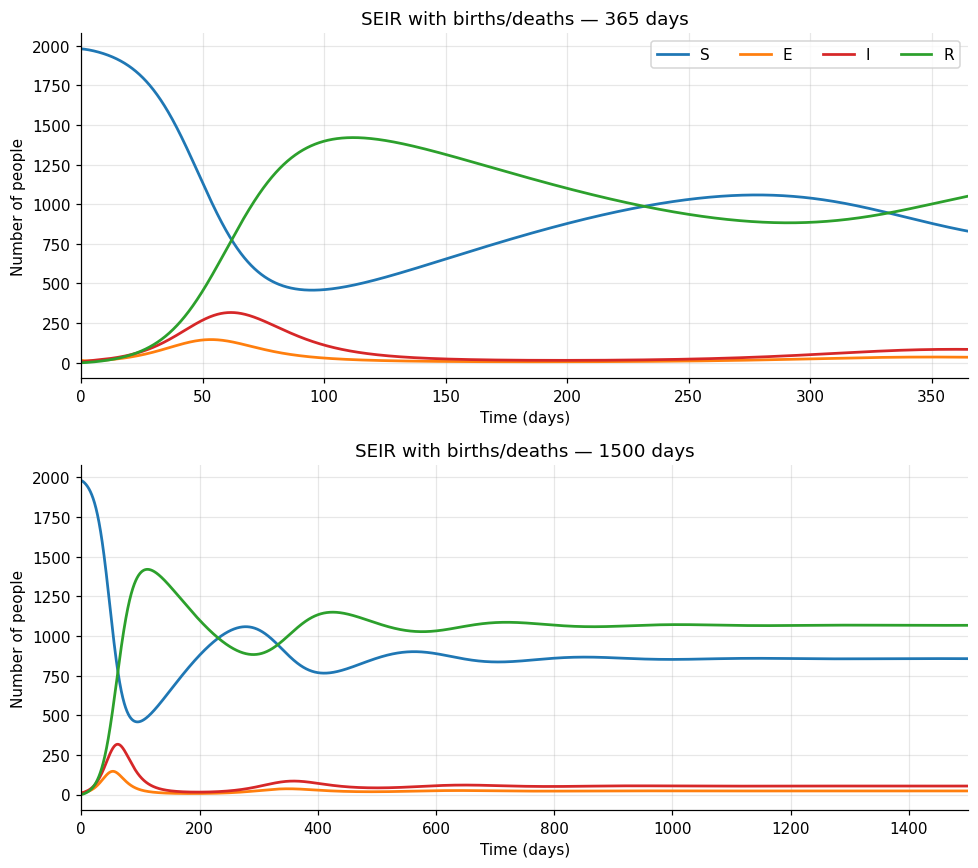

In [12]:
N = 2000
seir_ic = dict(S0=1980, E0=15, I0=5, R0=0)
beta, gamma, sigma, mu = 0.125e-3, 0.1, 0.25, 0.005

def plot_seir(ax, t, S, E, I, R, title):
    for y, c in zip((S, E, I, R), "SEIR"):
        ax.plot(t, y, color=COL[c], lw=1.8, label=c)
    ax.set(xlabel="Time (days)", ylabel="Number of people", title=title, xlim=(0, t[-1]))

fig, axes = plt.subplots(2, 1, figsize=(9, 8))
sims = {}
for ax, T in zip(axes, [365, 1500]):
    sims[T] = simulate_seir(N, **seir_ic, beta=beta, gamma=gamma, sigma=sigma, mu=mu, t_end=T, dt=0.1)
    plot_seir(ax, *sims[T], f"SEIR with births/deaths — {T} days")
axes[0].legend(ncol=4, loc="upper right")
fig.tight_layout(); fig.savefig("figures/D_seir_365_1500.png", dpi=200)
plt.show()

Zoom in

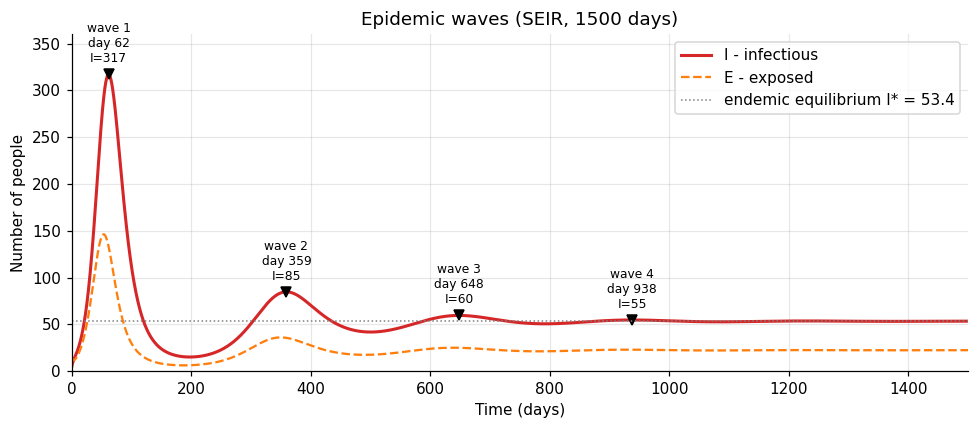

In [16]:
t, S, E, I, R = sims[1500]
peaks, _ = find_peaks(I, prominence=0.5)
troughs, _ = find_peaks(-I, prominence=0.5)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t, I, color=COL["I"], lw=2, label="I - infectious")
ax.plot(t, E, color=COL["E"], lw=1.5, ls="--", label="E - exposed")
ax.plot(t[peaks], I[peaks], "kv")
for j, p in enumerate(peaks, 1):
    ax.annotate(f"wave {j}\nday {t[p]:.0f}\nI={I[p]:.0f}", (t[p], I[p]), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=8)
I_star = mu * (N - N / (beta * N * sigma / ((sigma + mu) * (gamma + mu)))) / beta \
         / (N / (beta * N * sigma / ((sigma + mu) * (gamma + mu))))
ax.axhline(I_star, color="gray", ls=":", lw=1, label=f"endemic equilibrium I* = {I_star:.1f}")
ax.set(xlabel="Time (days)", ylabel="Number of people", title="Epidemic waves (SEIR, 1500 days)",
       xlim=(0, 1500), ylim=(0, 360))
ax.legend()
fig.tight_layout(); fig.savefig("figures/D_waves.png", dpi=200)
plt.show()

### iii. Epidemic waves

In [14]:
incidence = beta * S * I
bounds = np.r_[0, troughs, len(t) - 1]
print(f"{'wave':>4} {'peak day':>9} {'peak I':>8} {'from day':>9} {'to day':>7} {'new infections':>15}")
for j, p in enumerate(peaks):
    a, b = bounds[j], bounds[j + 1]
    size = np.trapezoid(incidence[a:b + 1], t[a:b + 1])
    print(f"{j+1:>4} {t[p]:>9.1f} {I[p]:>8.1f} {t[a]:>9.0f} {t[b]:>7.0f} {size:>15.0f}")
print("\nTrough values of I:", ", ".join(f"day {t[q]:.0f}: {I[q]:.1f}" for q in troughs))
print(f"Mean spacing between peaks: {np.diff(t[peaks]).mean():.0f} days")

# Linearised period of damped oscillations about the endemic equilibrium
R0_seir = beta * N * sigma / ((sigma + mu) * (gamma + mu))
A = 1 / (mu * (R0_seir - 1))              # mean age at infection
G = 1 / sigma + 1 / gamma                 # generation time (latent + infectious)
print(f"Theory: period ~ 2*pi*sqrt(A*G) = {2*np.pi*np.sqrt(A*G):.0f} days  (A = {A:.0f} d, G = {G:.0f} d)")

wave  peak day   peak I  from day  to day  new infections
   1      61.6    316.9         0     198            2182
   2     359.2     84.8       198     500            1675
   3     648.1     59.6       500     792            1661
   4     938.0     54.7       792    1083            1660

Trough values of I: day 198: 15.1, day 500: 41.8, day 792: 50.6, day 1083: 52.7
Mean spacing between peaks: 292 days
Theory: period ~ 2*pi*sqrt(A*G) = 288 days  (A = 150 d, G = 14 d)


The infections follow damped oscillations: a large initial epidemic, then progressively smaller waves about 290 days apart that settle into an endemic equilibrium of $I^* \approx 53$.

| wave | peak day | peak $I$ | above $I^*$ |
|---|---|---|---|
| 1 | 62 | 317 | 264 |
| 2 | 359 | 85 | 31 |
| 3 | 648 | 60 | 6 |
| 4 | 938 | 55 | 1 |

The 365-day run shows essentially one major wave: infections peak on day 62, fall to about 15 on day 198, and begin rising again, with a small second wave peaking just inside the window on day 359. The 1500-day run shows that this rise is the start of a sequence of waves, each roughly one fifth the amplitude of the previous one, with later waves indistinguishable from the equilibrium. The mechanism is overshoot and replenishment: the first wave pushes $S$ far below the threshold $N/R_0$, births slowly refill it at $\mu N = 10$ people per day, and once $S$ climbs back above $N/R_0$, $R_t$ exceeds 1 and a new wave starts. Each overshoot is smaller than the last, so the oscillations damp out. The observed spacing of about 290 days matches the classical estimate $2\pi\sqrt{AG} \approx 288$ days, where $A = 1/[\mu(R_0 - 1)] \approx 150$ days is the mean age at infection and $G = 1/\sigma + 1/\gamma = 14$ days is the generation time.

### iv

In [ ]:
# Part D(iv): Reproduction number and equilibrium

R0_sir = beta * N / gamma

R0_seir = (
    beta * N * sigma
    / ((sigma + mu) * (gamma + mu))
)

S_star = N / R0_seir

# Long-term simulation result
t, S, E, I, R = sims[1500]

S_final = S[-1]

print(f"SIR R0: {R0_sir:.4f}")
print(f"SEIR R0: {R0_seir:.4f}")

print(f"Theoretical S*: {S_star:.2f}")
print(f"Simulated S(1500): {S_final:.2f}")

print(f"Difference: {S_final - S_star:.2f}")

SIR R0: 2.5000
SEIR R0: 2.3343
Theoretical S*: 856.80
Simulated S(1500): 856.92
Difference: 0.12


The SEIR model gives $R_0 = 2.33$, a bit lower than the 2.50 from the SIR model in Part C. The difference comes from deaths, not from the latent period itself: about 2% of exposed people die before they become infectious, and deaths also shorten the average infectious period from 10 to about 9.5 days. If we set $\mu = 0$, the SEIR formula goes back to $\beta N/\gamma = 2.5$, so the latent period only delays infections without preventing any.

In the long run, the simulation settles at $S(1500) = 856.9$, almost exactly $N/R_0 = 856.8$ (the 0.12 gap is the last bit of the damped oscillation). At this point $R_t = R_0 S/N = 1$, so each infected person passes the infection to exactly one other person on average, and the disease neither grows nor dies out but stays endemic at about 53 infectious people. New susceptibles arriving through births are balanced by those lost to infection and natural death. This also means about $1 - 1/R_0 \approx 57\%$ of the population is not susceptible at equilibrium, which is the herd-immunity threshold: vaccinating more than 57% of newborns would keep $S$ below $N/R_0$ and eliminate the disease.

### v 

In [17]:
mu_real = 1 / (80 * 365)
t_r, S_r, E_r, I_r, R_r = simulate_seir(N, **seir_ic, beta=beta, gamma=gamma, sigma=sigma, mu=mu_real, t_end=1500, dt=0.1)
k_r = I_r.argmax()
R0_r = beta * N * sigma / ((sigma + mu_real) * (gamma + mu_real))
A_r = 1 / (mu_real * (R0_r - 1))
print(f"Peak: day {t_r[k_r]:.0f}, I = {I_r[k_r]:.0f}; I(1500) = {I_r[-1]:.1e}")
print(f"Predicted wave spacing: {2*np.pi*np.sqrt(A_r*G)/365:.1f} years")

Peak: day 58, I = 335; I(1500) = 2.0e-34
Predicted wave spacing: 9.0 years


The exposed compartment adds a delay between being infected and being able to infect others. With $\sigma = 0.25$ per day, people spend about 4 days in E, so one generation of transmission takes about 14 days instead of 10. This slows the early growth and stretches the time between waves, but it does not change how many people each case eventually infects (see iv). The waves themselves come from births and deaths: births add 10 new susceptibles per day, which slowly refills the pool that the first wave used up, and each refill sets off a smaller wave until the system settles at the endemic equilibrium.

The lifespan of 200 days implied by $\mu = 0.005$ is far too short for humans. With a realistic 80-year lifespan ($\mu \approx 3.4 \times 10^{-5}$ per day), the 1500-day run shows only one wave, peaking on day 58 with about 335 infected, after which infections keep falling toward zero. Susceptibles are now refilled so slowly that the next wave would be about 9 years away. In a real population of 2000 people, the number infected would drop below one long before then and the disease would simply die out, something a deterministic model with fractional people cannot capture.

## E. Sensitivity Analysis
### i&ii

In [18]:
betas = np.linspace(0.05e-3, 0.25e-3, 21)
gammas = np.linspace(0.05, 0.25, 21)
peak = np.zeros((len(gammas), len(betas)))
total = np.zeros_like(peak)
peak_day = np.zeros_like(peak)

for i, g in enumerate(gammas):
    for j, b in enumerate(betas):
        t, S, E, I, R = simulate_seir(N, **seir_ic, beta=b, gamma=g, sigma=sigma, mu=mu, t_end=365, dt=0.1)
        peak[i, j] = I.max()
        peak_day[i, j] = t[I.argmax()]
        total[i, j] = np.trapz(b * S * I, t)

R0_grid = betas[None, :] * N * sigma / ((sigma + mu) * (gammas[:, None] + mu))
print(peak.size, "simulations")

/var/folders/pk/ctgq51p975ng_k7614bsw5vw0000gp/T/ipykernel_8872/3442861756.py:12: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  total[i, j] = np.trapz(b * S * I, t)


441 simulations


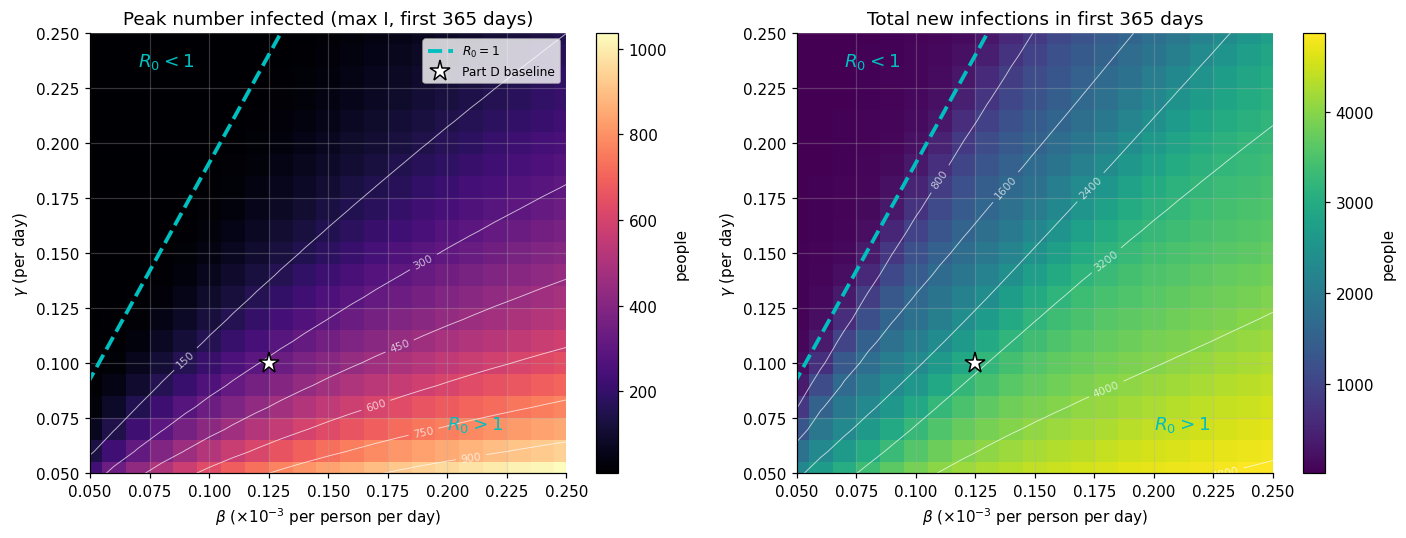

In [19]:
def r0_line(gam):
    # beta such that R0 = 1 for a given gamma
    return (sigma + mu) * (gam + mu) / (N * sigma)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, Z, title, cmap in [(axes[0], peak, "Peak number infected (max I, first 365 days)", "magma"),
                           (axes[1], total, "Total new infections in first 365 days", "viridis")]:
    pc = ax.pcolormesh(betas * 1e3, gammas, Z, shading="nearest", cmap=cmap)
    cs = ax.contour(betas * 1e3, gammas, Z, levels=6, colors="white", linewidths=0.6, alpha=0.7)
    ax.clabel(cs, fmt="%d", fontsize=7)
    g_line = np.linspace(gammas[0], gammas[-1], 100)
    ax.plot(r0_line(g_line) * 1e3, g_line, "c--", lw=2.5, label=r"$R_0 = 1$")
    ax.plot(0.125, 0.1, "w*", ms=14, mec="k", label="Part D baseline")
    ax.set(xlabel=r"$\beta$ ($\times10^{-3}$ per person per day)", ylabel=r"$\gamma$ (per day)", title=title,
           xlim=(betas[0] * 1e3, betas[-1] * 1e3), ylim=(gammas[0], gammas[-1]))
    ax.text(0.07, 0.235, r"$R_0<1$", color="c", fontsize=12, fontweight="bold")
    ax.text(0.2, 0.07, r"$R_0>1$", color="c", fontsize=12, fontweight="bold")
    fig.colorbar(pc, ax=ax, label="people")
    ax.legend(loc="upper right", fontsize=8, framealpha=0.8) if ax is axes[0] else None
fig.tight_layout(); fig.savefig("figures/E_heatmaps.png", dpi=200)
plt.show()

In [20]:
# Additional analysis: beta vs gamma at equal R0 (hypothesis iii)
def seir_out(b, g, T=365):
    t, S, E, I, R = simulate_seir(N, **seir_ic, beta=b, gamma=g, sigma=sigma, mu=mu, t_end=T, dt=0.1)
    return I.max(), t[I.argmax()], np.trapezoid(b * S * I, t)

b0, g0 = 0.125e-3, 0.1
base = seir_out(b0, g0)
print(f"Baseline: R0 = {R0_seir:.2f}, peak I = {base[0]:.0f} on day {base[1]:.0f}, new infections = {base[2]:.0f}\n")
print(f"{'change':>32} {'R0':>6} {'peak I':>7} {'peak day':>9} {'new inf.':>9}")
for f in [1.2, 1 / 1.2]:
    g_eq = (g0 + mu) / f - mu       # gamma giving the same R0 change as beta*f
    for label, b, g in [(f"beta x {f:.2f}", b0 * f, g0), (f"gamma -> {g_eq:.4f} (same R0)", b0, g_eq)]:
        r0 = b * N * sigma / ((sigma + mu) * (g + mu))
        pk, day, tot = seir_out(b, g)
        print(f"{label:>32} {r0:>6.2f} {pk:>7.0f} {day:>9.0f} {tot:>9.0f}")

# Thresholds for R0 < 1 starting from the baseline
beta_crit = r0_line(g0)                              # beta giving R0 = 1 at gamma = 0.1
gamma_crit = b0 * N * sigma / (sigma + mu) - mu      # gamma giving R0 = 1 at beta = 0.125e-3
print(f"\nR0 = 1 needs beta < {beta_crit*1e3:.3f}e-3 ({1 - beta_crit/b0:.0%} cut) or gamma > {gamma_crit:.3f}/day")

Baseline: R0 = 2.33, peak I = 317 on day 62, new infections = 3075

                          change     R0  peak I  peak day  new inf.
                     beta x 1.20   2.80     408        52      3560
       gamma -> 0.0825 (same R0)   2.80     433        58      3517
                     beta x 0.83   1.95     227        75      2442
       gamma -> 0.1210 (same R0)   1.95     212        66      2485

R0 = 1 needs beta < 0.054e-3 (57% cut) or gamma > 0.240/day


### iii. Interpretation and public-health implications

The sensitivity analysis shows that higher transmission rates produce larger peaks and more cumulative infections, whereas higher recovery rates reduce both, and the $R_0 = 1$ line separates combinations that cause an outbreak from those where infections die out. Since $\beta$ corresponds to contact-based transmission, social distancing, masking and reduced contacts move the system toward this line; from the baseline, $\beta$ would have to fall by about 57% to reach $R_0 < 1$, while smaller reductions mainly lower and delay the peak. Since $\gamma$ corresponds to how quickly people stop being infectious, timely treatment, testing and isolation have a similar effect, although $\gamma$ would need to exceed about 0.24 per day (an infectious period under about 4 days), which is hard to achieve by treatment alone, so combining both types of measures is the most realistic way to push $R_0$ below 1. The heatmap contours run roughly parallel to the $R_0 = 1$ line, so outcomes depend mainly on $R_0$, but not entirely: in the equal-$R_0$ comparison, lowering $\gamma$ gives a higher peak than raising $\beta$ by the same factor (433 versus 408 at $R_0 = 2.8$), so $R_0$ alone does not fully describe the epidemic.